# MS Thesis Work
### Summer project part
#### *Single Massive particle trajectory around a Black Hole*

In [2]:
#%pip install sympy

In [3]:
import sympy as sp
sp.init_printing()
import numpy as np

In [4]:
def generate_kerr_christoffels():
    # 1. Define symbolic variables (using geometrized units G = c = 1)
    t, r, theta, phi = sp.symbols('t r theta phi', real=True)
    a = sp.symbols('a', real=True) # Black hole spin parameter
    
    coords = [t, r, theta, phi]
    N = len(coords)
    
    # 2. Define the helper functions from Prof. Garain's paper
    sigma = r**2 + a**2 * sp.cos(theta)**2
    Sigma = r**2 - 2*r + a**2
    
    # 3. Initialize empty metric tensor (4x4 matrix)
    g = sp.Matrix.zeros(N, N)
    
    # 4. Populate non-zero components exactly per the paper's metric
    g[0, 0] = -(1 - (2*r)/sigma)
    g[0, 3] = -(2*a*r * sp.sin(theta)**2) / sigma
    g[3, 0] = g[0, 3]
    g[1, 1] = sigma / Sigma
    g[2, 2] = sigma
    g[3, 3] = (r**2 + a**2 + (2*(a**2)*r * sp.sin(theta)**2)/sigma) * sp.sin(theta)**2
    
    print("Calculating inverse metric tensor...")
    g_inv = g.inv()
    
    # 5. Compute Christoffel symbols
    # Gamma[mu, alpha, beta]
    Gamma = np.zeros((N, N, N), dtype=object)
    
    print("Computing Christoffel symbols (this may take a minute)...")
    for mu in range(N):
        for alpha in range(N):
            for beta in range(N):
                gamma_element = 0
                for rho in range(N):
                    # Implementation of the GR Christoffel equation
                    term1 = sp.diff(g[rho, beta], coords[alpha])
                    term2 = sp.diff(g[alpha, rho], coords[beta])
                    term3 = sp.diff(g[alpha, beta], coords[rho])
                    
                    gamma_element += 0.5 * g_inv[mu, rho] * (term1 + term2 - term3)
                
                Gamma[mu, alpha, beta] = sp.simplify(gamma_element)
                
    print("Christoffel symbols calculated successfully.")
    return coords, a, Gamma


In [5]:
if __name__ == "__main__":
    coords, a, Gamma = generate_kerr_christoffels()
    
    # Example: Print Gamma^r_{phi phi} to check output
    print("\nExample Symbol (Gamma^r_p_p):")
    sp.pprint(Gamma[1, 3, 3])

Calculating inverse metric tensor...
Computing Christoffel symbols (this may take a minute)...
Christoffel symbols calculated successfully.

Example Symbol (Gamma^r_p_p):
                            ⎛                                                                      2⎞        
⎛       2        2        ⎞ ⎜     2  2    2       2 ⎛ 2    2       2⎞    2        ⎛ 2    2       2⎞ ⎟    2   
⎝- 1.0⋅a  - 1.0⋅r  + 2.0⋅r⎠⋅⎝- 2⋅a ⋅r ⋅sin (θ) + a ⋅⎝a ⋅cos (θ) + r ⎠⋅sin (θ) + r⋅⎝a ⋅cos (θ) + r ⎠ ⎠⋅sin (θ)
─────────────────────────────────────────────────────────────────────────────────────────────────────────────
                                                              3                                              
                                             ⎛ 2    2       2⎞                                               
                                             ⎝a ⋅cos (θ) + r ⎠                                               


In [6]:
def build_integration_engine(r_sym, theta_sym, a_sym, Gamma_sym):
    print("\nConverting symbolic Christoffel symbols to fast numerical functions...")
    
    # Convert the numpy array of sympy expressions to a standard list for lambdify
    Gamma_list = Gamma_sym.tolist()
    
    # lambdify creates a fast numpy-compatible function. 
    # It takes (r, theta, a) as inputs and returns the full 4x4x4 Gamma array.
    Gamma_func = sp.lambdify((r_sym, theta_sym, a_sym), Gamma_list, 'numpy')
    print("Numerical conversion complete!")
    
    return Gamma_func

In [7]:
def geodesic_odes(tau, Y, a_val, Gamma_func):
    """
    The differential equations for the geodesic path.
    tau: proper time (the independent variable for the solver)
    Y: state vector [t, r, theta, phi, u^t, u^r, u^theta, u^phi]
    """
    # Extract coordinates and 4-velocities from the state vector
    coords = Y[:4]
    u = Y[4:]  
    
    r_current = Y[1]
    theta_current = Y[2]
    
    # Evaluate the 64 Christoffel symbols at the particle's exact current position
    G = Gamma_func(r_current, theta_current, a_val)
    
    # Initialize the array for 4-acceleration (du^mu / dtau)
    du = np.zeros(4)
    
    # Compute the geodesic equation: du^mu/dtau = - Gamma^mu_{alpha beta} u^alpha u^beta
    for mu in range(4):
        for alpha in range(4):
            for beta in range(4):
                du[mu] -= G[mu][alpha][beta] * u[alpha] * u[beta]
                
    # Return the derivatives: [dt/dtau, dr/dtau, dtheta/dtau, dphi/dtau, du^t/dtau, ...]
    return [u[0], u[1], u[2], u[3], du[0], du[1], du[2], du[3]]

In [8]:
if __name__ == "__main__":
    # 1. Generate the symbolic math (the current code)
    coords, a, Gamma = generate_kerr_christoffels()
    
    # 2. Extract the specific symbols needed
    t_sym, r_sym, theta_sym, phi_sym = coords
    
    # 3. Build the fast numerical function
    Gamma_numeric = build_integration_engine(r_sym, theta_sym, a, Gamma)
    
    # Quick test: Evaluate the symbols at r=5, theta=pi/2, a=0.9
    test_eval = Gamma_numeric(5.0, np.pi/2, 0.9)
    print(f"\nTest evaluation successful. Array shape: {np.shape(test_eval)}")

Calculating inverse metric tensor...
Computing Christoffel symbols (this may take a minute)...
Christoffel symbols calculated successfully.

Converting symbolic Christoffel symbols to fast numerical functions...
Numerical conversion complete!

Test evaluation successful. Array shape: (4, 4, 4)


In [9]:
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

In [10]:
# --- 1. Helper functions for the Metric and Initial State ---
def get_metric_components(r, theta, a):
    """Calculates specific metric components needed for the u^t constraint."""
    sigma = r**2 + a**2 * np.cos(theta)**2
    g_tt = -(1 - (2*r)/sigma)
    g_tphi = -(2*a*r * np.sin(theta)**2) / sigma
    g_phiphi = (r**2 + a**2 + (2*(a**2)*r * np.sin(theta)**2)/sigma) * np.sin(theta)**2
    return g_tt, g_tphi, g_phiphi

def calculate_initial_ut(r, theta, a, u_phi):
    """Solves the quadratic equation for u^t to ensure u_mu u^mu = -1"""
    g_tt, g_tphi, g_phiphi = get_metric_components(r, theta, a)
    
    A = g_tt
    B = 2 * g_tphi * u_phi
    C = g_phiphi * (u_phi**2) + 1
    
    # Quadratic formula (taking the positive root for forward time progression)
    discriminant = B**2 - 4*A*C
    if discriminant < 0:
        raise ValueError("Unphysical initial conditions: Particle requires faster-than-light travel.")
    
    u_t = (-B - np.sqrt(discriminant)) / (2 * A)
    return u_t

In [11]:
def calculate_initial_ut(r, theta, a, u_phi):
    """Solves g_tt(u^t)^2 + 2g_tphi u^t u_phi + g_phiphi(u_phi)^2 + 1 = 0"""
    g_tt, g_tphi, g_phiphi = get_metric_components(r, theta, a)
    
    A = g_tt
    B = 2 * g_tphi * u_phi
    C = g_phiphi * (u_phi**2) + 1
    
    discriminant = B**2 - 4*A*C
    if discriminant < 0:
        raise ValueError("Unphysical initial conditions! Try lowering u_phi.")
    
    # We take the negative root because g_tt is negative, ensuring u^t > 0 (forward in time)
    u_t = (-B - np.sqrt(discriminant)) / (2 * A)
    return u_t

In [12]:
# --- 2. The Event Horizon Stop Condition ---
def event_horizon_crossing(tau, Y, a_val, Gamma_func):
    """Event function to stop the solver when r reaches the outer event horizon."""
    r = Y[1]
    r_horizon = 1 + np.sqrt(1 - a_val**2)
    return r - r_horizon

event_horizon_crossing.terminal = True
event_horizon_crossing.direction = -1 # Triggers when crossing from outside to inside

##### Case A: Prograde Plunge:
a_spin = 0.95 (Fast spinning black hole)
r_initial = 10.0         
theta_initial = np.pi/2  
phi_initial = 0.0        
u_phi_initial = 0.022 (Lowered from 0.035 to guarantee a plunge!)

##### Case B: Retrograde Plunge:
a_spin = 0.95
 r_initial = 10.0         
theta_initial = np.pi/2  
phi_initial = 0.0        
u_phi_initial = -0.022 (Negative value means orbiting in reverse ()


Initial 4-velocity vector: u^t=1.1397, u^r=0, u^theta=0, u^phi=0.0219279242150597
Simulating particle trajectory... (dropping into the black hole)


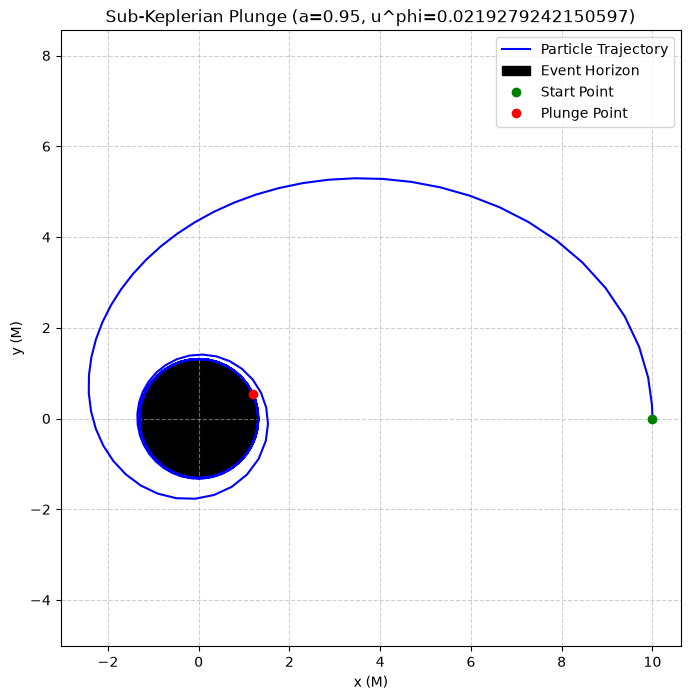

Simulation Complete!


In [17]:
# --- 3. The Main Simulation Execution ---
if __name__ == "__main__":
    # Parameters based on notes (Equatorial +l sub-Keplerian plunge)
    a_spin = 0.95            # Fast spinning black hole
    r_initial = 10.0         # Start at 10 M (outside ISCO)
    theta_initial = np.pi/2  # Equatorial plane
    phi_initial = 0.0        # Start on the x-axis
    
    # Sub-Keplerian angular velocity (play with this number later!)
    u_phi_initial = 0.0219279242150597    
    
    # Calculate u^t
    u_t_initial = calculate_initial_ut(r_initial, theta_initial, a_spin, u_phi_initial)
    #u_t_initial = 1.1396861233204219
    
    print(f"\nInitial 4-velocity vector: u^t={u_t_initial:.4f}, u^r=0, u^theta=0, u^phi={u_phi_initial}")
    
    # Initial State Vector Y0
    Y0 = [0.0, r_initial, theta_initial, phi_initial, u_t_initial, 0.0, 0.0, u_phi_initial]
    
    # Proper time span (tau)
    tau_span = (0, 1000) 
    
    print("Simulating particle trajectory... (dropping into the black hole)")
    
    # Run the RK45 Solver
    solution = solve_ivp(
        fun=geodesic_odes,
        t_span=tau_span,
        y0=Y0,
        args=(a_spin, Gamma_numeric),
        events=event_horizon_crossing,
        method='RK45',
        rtol=1e-8, # Strict tolerances required for GR
        atol=1e-8
    )
    
    # --- 4. Plotting the Trajectory ---
    r_vals = solution.y[1]
    phi_vals = solution.y[3]
    
    # Convert polar to Cartesian for standard 2D plotting
    x_vals = r_vals * np.cos(phi_vals)
    y_vals = r_vals * np.sin(phi_vals)
    
    r_horizon = 1 + np.sqrt(1 - a_spin**2)
    
    plt.figure(figsize=(8, 8))
    plt.plot(x_vals, y_vals, label='Particle Trajectory', color='blue')
    
    # Draw the Event Horizon
    horizon_circle = plt.Circle((0, 0), r_horizon, color='black', label='Event Horizon')
    plt.gca().add_patch(horizon_circle)
    
    plt.plot(x_vals[0], y_vals[0], 'go', label='Start Point')
    plt.plot(x_vals[-1], y_vals[-1], 'ro', label='Plunge Point')
    
    plt.title(f"Sub-Keplerian Plunge (a={a_spin}, u^phi={u_phi_initial})")
    plt.xlabel("x (M)")
    plt.ylabel("y (M)")
    plt.axis('equal')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()
    plt.show()
    print("Simulation Complete!")

Generating 3D Visualization...


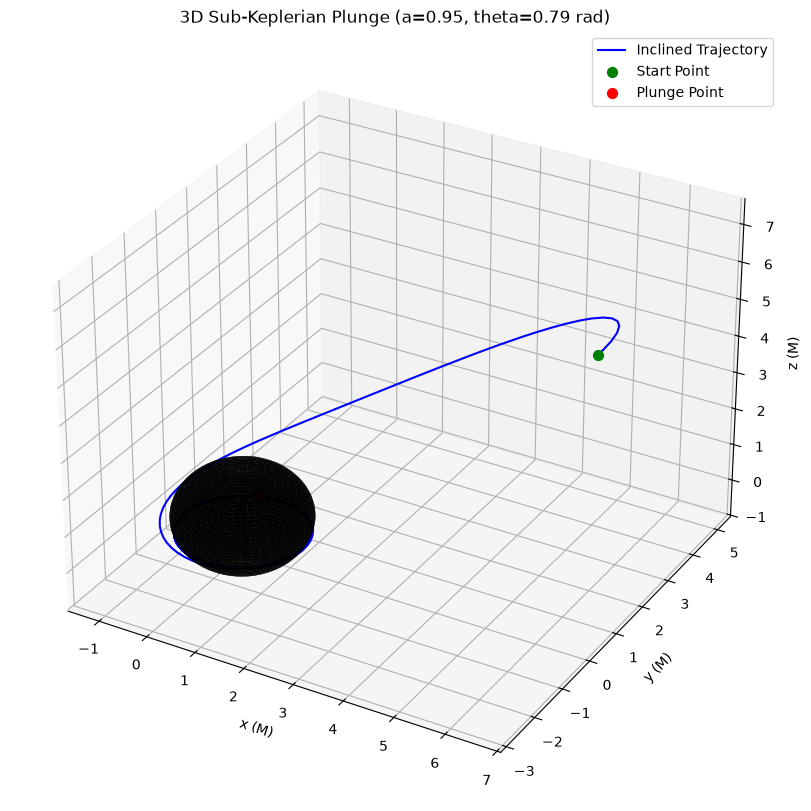

In [14]:
import matplotlib.pyplot as plt

if __name__ == "__main__":
    a_spin = 0.95            
    r_initial = 10.0         
    
    # Change the initial theta to put the particle above the equator
    theta_initial = np.pi / 4  # 45-degree inclination
    phi_initial = 0.0        
    
    # Prograde sub-Keplerian velocity
    u_phi_initial = 0.022    
    
    u_t_initial = calculate_initial_ut(r_initial, theta_initial, a_spin, u_phi_initial)
    Y0 = [0.0, r_initial, theta_initial, phi_initial, u_t_initial, 0.0, 0.0, u_phi_initial]
    
    # Run the solver (same as before)
    solution = solve_ivp(
        fun=geodesic_odes, t_span=(0, 1000), y0=Y0, 
        args=(a_spin, Gamma_numeric), events=event_horizon_crossing, 
        method='RK45', rtol=1e-8, atol=1e-8
    )
    
    # --- 4. 3D Plotting the Trajectory ---
    print("Generating 3D Visualization...")
    
    r_vals = solution.y[1]
    theta_vals = solution.y[2]
    phi_vals = solution.y[3]
    
    # Convert Spherical (r, theta, phi) to Cartesian (x, y, z)
    x_vals = r_vals * np.sin(theta_vals) * np.cos(phi_vals)
    y_vals = r_vals * np.sin(theta_vals) * np.sin(phi_vals)
    z_vals = r_vals * np.cos(theta_vals)
    
    r_horizon = 1 + np.sqrt(1 - a_spin**2)
    
    # Setup 3D Figure
    fig = plt.figure(figsize=(10, 10))
    ax = fig.add_subplot(111, projection='3d')
    
    # Plot the particle path
    ax.plot(x_vals, y_vals, z_vals, label='Inclined Trajectory', color='blue', linewidth=1.5)
    
    # Generate a Black Hole Sphere
    u = np.linspace(0, 2 * np.pi, 50)
    v = np.linspace(0, np.pi, 50)
    x_bh = r_horizon * np.outer(np.cos(u), np.sin(v))
    y_bh = r_horizon * np.outer(np.sin(u), np.sin(v))
    z_bh = r_horizon * np.outer(np.ones(np.size(u)), np.cos(v))
    
    # Plot the Event Horizon
    ax.plot_surface(x_bh, y_bh, z_bh, color='black', alpha=0.9)
    
    # Mark Start and Plunge points
    ax.scatter(x_vals[0], y_vals[0], z_vals[0], color='green', s=50, label='Start Point')
    ax.scatter(x_vals[-1], y_vals[-1], z_vals[-1], color='red', s=50, label='Plunge Point')
    
    # Formatting
    ax.set_title(f"3D Sub-Keplerian Plunge (a={a_spin}, theta={theta_initial:.2f} rad)")
    ax.set_xlabel("x (M)")
    ax.set_ylabel("y (M)")
    ax.set_zlabel("z (M)")
    
    # Ensure equal scaling so the black hole doesn't look stretched
    max_range = np.array([x_vals.max()-x_vals.min(), y_vals.max()-y_vals.min(), z_vals.max()-z_vals.min()]).max() / 2.0
    mid_x = (x_vals.max()+x_vals.min()) * 0.5
    mid_y = (y_vals.max()+y_vals.min()) * 0.5
    mid_z = (z_vals.max()+z_vals.min()) * 0.5
    ax.set_xlim(mid_x - max_range, mid_x + max_range)
    ax.set_ylim(mid_y - max_range, mid_y + max_range)
    ax.set_zlim(mid_z - max_range, mid_z + max_range)
    
    ax.legend()
    plt.show()

In [19]:
# Extract the arrays from the solver
tau_numerical = solution.t
r_numerical = solution.y[1]
theta_numerical = solution.y[2]
phi_numerical = solution.y[3]

# Save the arrays to a lightweight binary file in your folder
np.savez('numerical_trajectory_1.npz', tau=tau_numerical, r=r_numerical, theta=theta_numerical, phi=phi_numerical)
print("Numerical trajectory saved to 'numerical_trajectory_1.npz'!")

Numerical trajectory saved to 'numerical_trajectory_1.npz'!


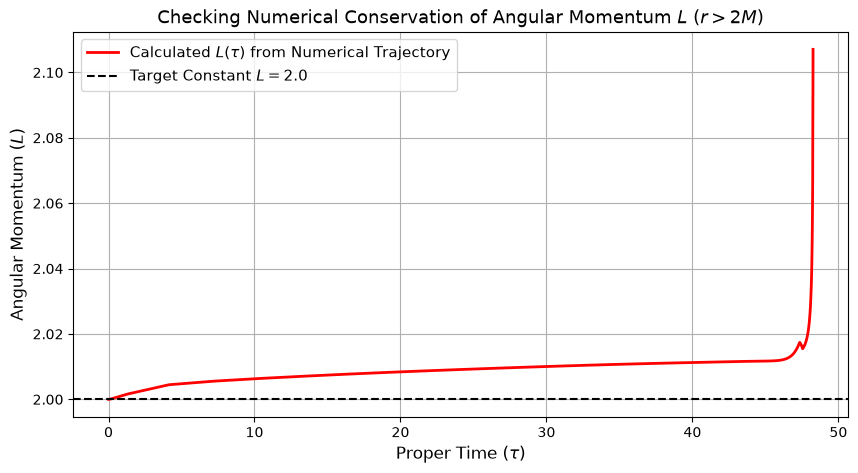

In [53]:
import numpy as np
import matplotlib.pyplot as plt

data = np.load('numerical_trajectory_1.npz')
tau = data['tau']
r = data['r']
phi = data['phi']

M = 1.0
a = 0.95
L = g_tphi*u_t_initial + g_phiphi*u_phi_initial

# Extracting velocities
# u^phi = d(phi)/d(tau), u^r = d(r)/d(tau)
u_phi = np.gradient(phi, tau)
u_r = np.gradient(r, tau)

L_numerical = []

# u^t and L
L_numerical = []
tau_valid = []

for i in range(len(tau)):
    ri = r[i]
    
    # we'll stop before r=2M to avoid the singularity and getting a better picture of the L values
    if ri <= 1.325:
        break
        
    u_phi_i = u_phi[i]
    u_r_i = u_r[i]
    delta = ri**2 - 2*M*ri + a**2
    
    g_tt = -(1.0 - (2.0 * M / ri))
    g_tphi = -(2.0 * a * M) / ri
    g_rr = (ri**2) / delta
    g_phiphi = ri**2 + a**2 + (2.0 * (a**2) * M / ri)
    
    A = g_tt
    B = 2.0 * g_tphi * u_phi_i
    C = g_rr * (u_r_i**2) + g_phiphi * (u_phi_i**2) + 1.0
    
    disc = B**2 - 4*A*C
    if disc >= 0:
        ut_i = (-B - np.sqrt(disc)) / (2.0 * A)
        L_i = g_tphi * ut_i + g_phiphi * u_phi_i
        L_numerical.append(L_i)
        tau_valid.append(tau[i])

L_numerical = np.array(L_numerical)
tau_valid = np.array(tau_valid)

# plot
plt.figure(figsize=(10, 5))
plt.plot(tau_valid, L_numerical, 'r-', linewidth=2, label='Calculated $L(\\tau)$ from Numerical Trajectory')
plt.axhline(y=L_target, color='k', linestyle='--', label=f'Target Constant $L = {L_target}$')
plt.title("Checking Numerical Conservation of Angular Momentum $L$ ($r > 2M$)", fontsize=13)
plt.xlabel("Proper Time ($\\tau$)", fontsize=12)
plt.ylabel("Angular Momentum ($L$)", fontsize=12)
plt.grid(True)
plt.legend(fontsize=11)
plt.show()